# 039 — AdaBoost

Preparação central original. Fit apenas no treino de cada divisão. Seleção interna/CV dentro das 8.769 linhas; validação fixa de desenvolvimento com 2.193 linhas. Sem submissão automática.

Resultado real guardado; não foi iniciado novo treino.
Kaggle: por submeter
Configuração selecionada: {'params': {'base_depth': 2, 'learning_rate': 0.5}, 'label': 'base_depth=2, learning_rate=0.5', 'cv_macro_f1': [0.3170991198569063, 0.30090103017583975, 0.3266152730351407], 'cv_macro_f1_mean': 0.3148718076892956, 'cv_macro_f1_std': 0.013001010002140899, 'cv_accuracy_mean': 0.3544303797468354, 'cv_train_macro_f1_mean': 0.331484866032089}
CSV: {'path': 'submissions/submission_039_novo_modelo.csv', 'differences': {'submission_001_regressao_logistica(1).csv': 2288, 'submission_002_regressao_logistica_regularizada.csv': 2205, 'submission_004_arvore_decisao.csv': 2459, 'submission_012_mlp_perda_ponderada.csv': 2216, 'submission_013_mlp_arquitetura.csv': 2216, 'submission_014_xgboost_mlp.csv': 2074, 'submission_015_mlp_learning_rate.csv': 2159, 'submission_028_ensemble_features_dominio.csv': 2109, 'submission_029_catboost.csv': 2065, 'submission_031_catboost_ponderacao_suave.csv': 2030, 'sub

,parcela,Macro F1,accuracy
0,train,0.338197,0.366861
1,validation,0.323874,0.351117


,classe,escalão,F1,recall,support
0,0,15–17 anos,0.192308,0.121951,41
1,1,18–19 anos,0.310345,0.529412,34
2,2,20–24 anos,0.349206,0.275000,80
3,3,25–29 anos,0.292683,0.320000,75
4,4,30–34 anos,0.080645,0.055556,90
5,5,35–39 anos,0.332326,0.426357,129
6,6,40–44 anos,0.272152,0.250000,172
7,7,45–49 anos,0.328691,0.341040,173
8,8,50–54 anos,0.541436,0.541436,181
9,9,55–59 anos,0.497175,0.433498,203


,params,label,cv_macro_f1,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_train_macro_f1_mean
0,"{'base_depth': 1, 'learning_rate': 0.05}","base_depth=1, learning_rate=0.05","[0.03810587027788842, 0.038174220040382185, 0....",0.038130,0.000039,0.179382,0.038130
1,"{'base_depth': 1, 'learning_rate': 0.5}","base_depth=1, learning_rate=0.5","[0.038739700074894884, 0.056336904266632834, 0...",0.049641,0.009523,0.177671,0.051535
2,"{'base_depth': 2, 'learning_rate': 0.05}","base_depth=2, learning_rate=0.05","[0.2602850606140054, 0.2447558221125551, 0.263...",0.256289,0.010144,0.339948,0.255176
3,"{'base_depth': 2, 'learning_rate': 0.5}","base_depth=2, learning_rate=0.5","[0.3170991198569063, 0.30090103017583975, 0.32...",0.314872,0.013001,0.354430,0.331485


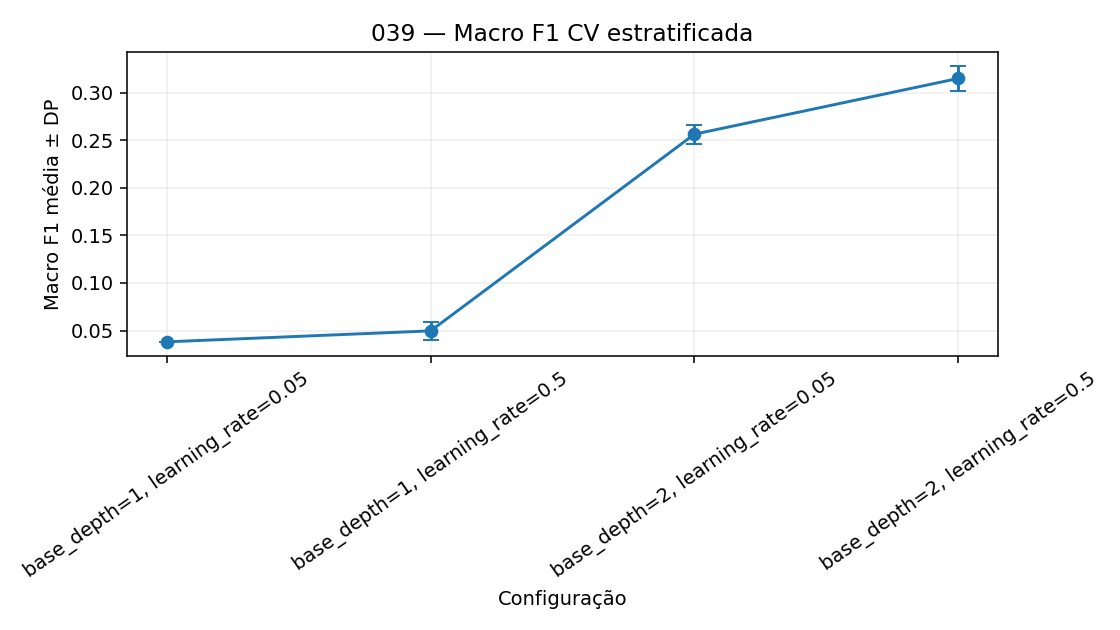

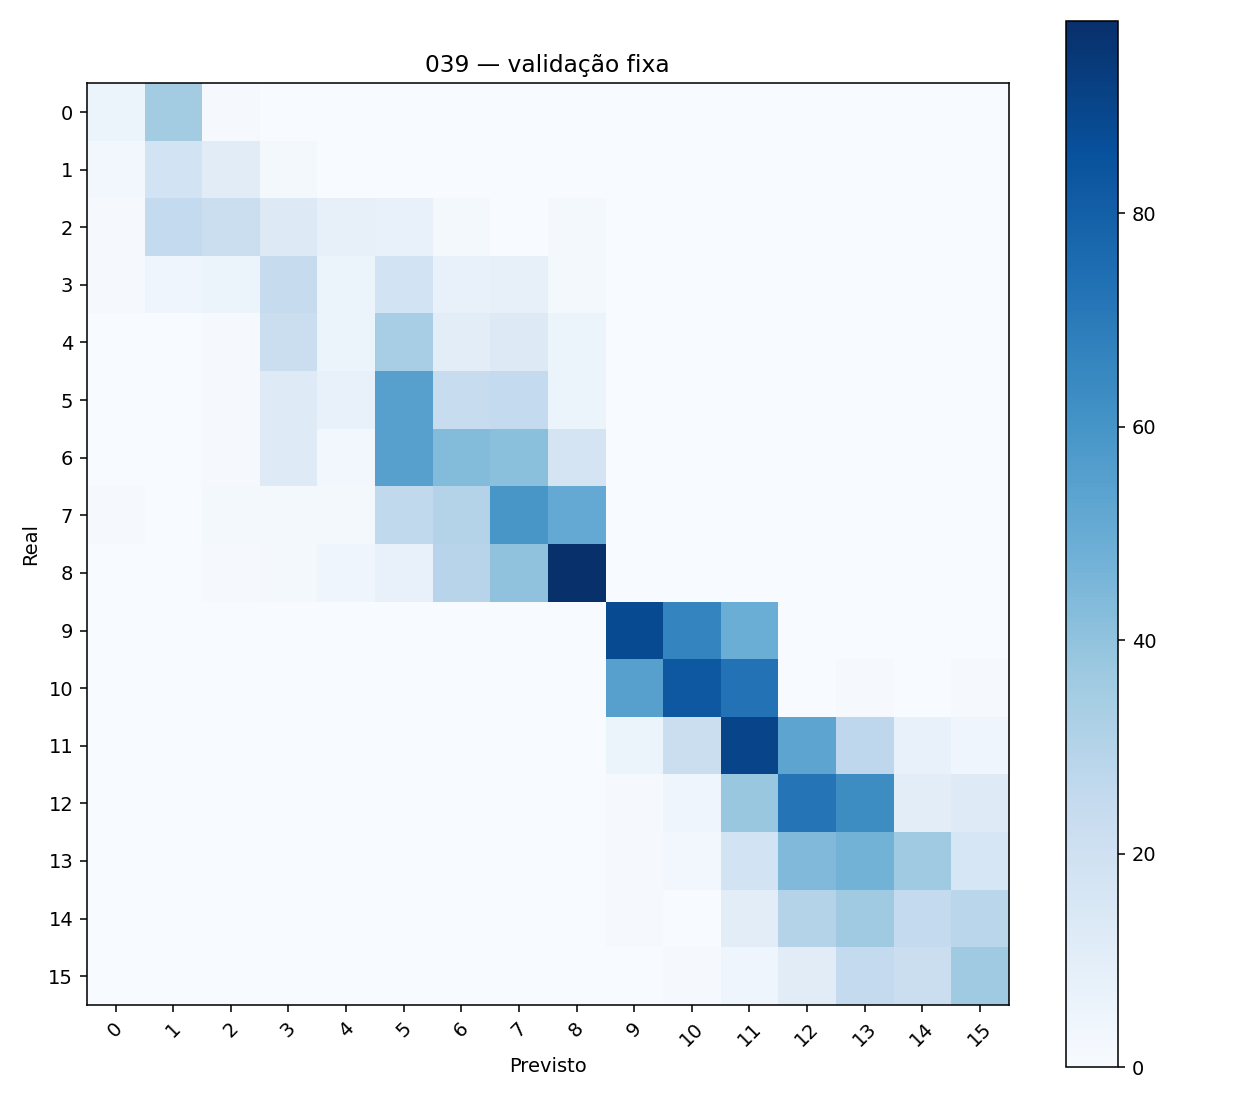

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/ver_resultados.py').is_file())
sys.path.insert(0, str(root))
from src.ver_resultados import carregar_resultado
result = carregar_resultado('039')
print('Resultado real guardado; não foi iniciado novo treino.')
print('Kaggle: por submeter')
selected = result.get('selected_internally', result.get('selected'))
if isinstance(selected, dict): selected = {k:v for k,v in selected.items() if k not in ['history', 'ae', 'folds']}
print('Configuração selecionada:', selected)
metrics = result.get('fixed_metrics', result.get('metrics', {}))
if metrics:
    display(pd.DataFrame([{'parcela':k, 'Macro F1':m['macro_f1'], 'accuracy':m['accuracy']} for k,m in metrics.items() if isinstance(m,dict) and 'macro_f1' in m]))
    if 'validation' in metrics:
        detail = metrics['validation'].get('per_class', metrics['validation'].get('classification_report', {}))
        if detail: display(pd.DataFrame(detail))
rows = result.get('candidates', result.get('results', []))
if rows:
    display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['history','ae','folds','age_profile_posthoc','sizes']} for r in rows]))
images = list((root/'reports').glob('experiencia_039_*.png')) + list((root/'reports').glob('039*.png'))
for p in sorted(set(images)): display(Image(filename=str(p)))
print('CSV:', result.get('submission'))
print('Notas:', result.get('note', ''))


## Conclusão e Decisão
- Data: 17/11
- Resultados baixos tanto localmente como no Kaggle (0,34). Esta configuração fica com baixa prioridade.
- Pontuação Kaggle: 0.34
- Melhorias: Se retomado, testar profundidade dos classificadores base e taxa de aprendizagem.